# Singapore Parliament 2015–2025 | Gender, marriage & normative adulthood: corpus audit

**Goal:** Determine whether the full parliamentary corpus contains *substantive* discourse relevant to marriage, singlehood, parenthood, youth transitions, and gendered care—not merely keyword mentions.

**Inputs:** `parliament_2015/speeches.csv` … `parliament_2025/speeches.csv` (or one consolidated CSV with a `date` column). No API or LLM required. **Outputs:** yearly counts, ranked candidate passages, a stratified human-review sample, a manual coding sheet and diagnostic charts.

**Important:** Lexical retrieval is a screening tool, not evidence that a speaker endorses a norm. Read the original passages before drawing conclusions. Results may be biased by speeches' length, parliamentary agenda and changes in dataset coverage.

In [2]:
from pathlib import Path
import re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('/Users/kemalgunay/PycharmProjects/sgparl/data')  # change to the parent directory of parliament_2015 ... parliament_2025
OUT = ROOT / 'family_norms_audit_outputs'
OUT.mkdir(parents=True, exist_ok=True)
YEARS = range(2015, 2026)
MIN_WORDS = 40
SEED = 42
pd.set_option('display.max_colwidth', 230)


## 1. Discover and validate input files

In [3]:
paths = []
for year in YEARS:
    paths.extend([p for p in [ROOT / f'parliament_{year}' / 'speeches.csv', ROOT / f'parliament_{year}' / 'data' / 'speeches.csv'] if p.exists()])
if not paths:
    paths = sorted(ROOT.glob('**/speeches.csv'))
if not paths and (ROOT / 'speeches.csv').exists():
    paths = [ROOT / 'speeches.csv']
paths = list(dict.fromkeys(paths))
print('Discovered files:', len(paths), '\n' + '\n'.join(map(str, paths)))
if not paths:
    raise FileNotFoundError('Set ROOT to the folder containing parliament_2015 ... parliament_2025.')
frames=[]
for p in paths:
    part=pd.read_csv(p, low_memory=False)
    if not {'date','text'}.issubset(part.columns):
        print('Skipped (missing date/text):', p); continue
    part['source_file']=str(p)
    frames.append(part)
if not frames: raise ValueError('No usable speech files found')
df=pd.concat(frames,ignore_index=True)
df['date']=pd.to_datetime(df['date'],errors='coerce')
df=df[df['date'].dt.year.between(2015,2025)].copy()
df['year']=df['date'].dt.year.astype(int)
df['text']=df['text'].fillna('').astype(str)
if 'speech_id' in df: df=df.drop_duplicates(subset=['speech_id'],keep='first')
else: df=df.drop_duplicates(subset=['date','text'],keep='first')
for c in ['topic_id','member_name','party','gender']:
    if c not in df: df[c]=pd.NA
for c in ['is_noise','is_chairing','is_appointment']:
    if c not in df: df[c]=False
    df[c]=df[c].astype(str).str.lower().isin(['true','1','yes'])
df['word_count']=df['text'].str.split().str.len()
print('Loaded',len(df),'speeches, years:',sorted(df.year.unique().tolist()))
display(df.groupby('year').agg(speeches=('text','size'),topics=('topic_id','nunique'),median_words=('word_count','median')))
missing=set(YEARS)-set(df.year.unique())
if missing: print('WARNING: Missing years:',sorted(missing))


Discovered files: 11 
/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2015/speeches.csv
/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2016/speeches.csv
/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2017/speeches.csv
/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2018/speeches.csv
/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2019/speeches.csv
/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2020/speeches.csv
/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2021/speeches.csv
/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2022/speeches.csv
/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2023/speeches.csv
/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2024/speeches.csv
/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2025/speeches.csv
Loaded 86736 speeches, years: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


,speeches,topics,median_words
year,,,
2015,3490,659,96.0
2016,5894,1175,74.0
2017,6222,1252,72.0
2018,6572,1220,69.0
2019,6902,1240,68.0
2020,6538,1309,76.0
2021,10049,2424,70.0
2022,10650,2599,65.5
2023,11213,2293,62.0


## 2. Screening vocabulary (editable)

Keep **target concepts** separate from **normative frames**. Avoid treating generic “family”, “single”, “young” as sufficient evidence of relevance.

In [4]:
CONCEPTS = {
 'marriage': [r'\bmarri(?:age|ages|ed|ying)\b',r'\bwedding(s)?\b',r'\bspous(?:e|es)\b'],
 'singlehood': [r'\bsingle(?:hood|s)?\b',r'\bunmarried\b',r'\bnever.married\b',r'\bchild(?:free|less)\b'],
 'parenthood': [r'\bparent(?:hood|ing|s)?\b',r'\bmother(?:hood|s)?\b',r'\bfather(?:hood|s)?\b',r'\bchildcare\b',r'\bchild.care\b'],
 'fertility': [r'\bfertility\b',r'\bbirth.rate(s)?\b',r'\btotal fertility rate\b',r'\bprocreat\w*\b',r'\bhav(?:e|ing) (?:a |more )?children\b'],
 'youth_transition': [r'\byoung adult(s)?\b',r'\byoung couple(s)?\b',r'\byouth\b',r'\bsettle down\b',r'\bstarting (?:a |their )?famil(?:y|ies)\b'],
 'gender_care': [r'\bgender\b',r'\bcaregiv(?:er|ers|ing)\b',r'\bmaternity\b',r'\bpaternity\b',r'\bworking mothers?\b',r'\bwork.life\b'],
 'family_formation': [r'\bfamily formation\b',r'\bstart(?:ing)? a family\b',r'\bform(?:ing)? a family\b',r'\bfamily planning\b']
}
FRAMES = {
 'demographic_responsibility':[r'\blow fertility\b',r'\bbirth.rate\b',r'\bageing population\b',r'\bpopulation decline\b',r'\breplacement rate\b'],
 'economic_constraints':[r'\baffordab\w*\b',r'\bhousing\b',r'\bfinancial burden\b',r'\bcost of living\b',r'\bjob security\b'],
 'individual_autonomy':[r'\bpersonal choice\b',r'\bindividual choice\b',r'\bchoose not to\b',r'\baspiration(s)?\b',r'\bown decision\b'],
 'familial_obligation':[r'\bfamily values\b',r'\bfamily responsibility\b',r'\bfilial piety\b',r'\bfamily as\b',r'\bduty to\b'],
 'gendered_care':[r'\bmothers?\b',r'\bfathers?\b',r'\bcaregiving\b',r'\bmaternity\b',r'\bpaternity\b',r'\bunpaid care\b'],
 'alternative_life_courses':[r'\bsinglehood\b',r'\bunmarried\b',r'\bchildless\b',r'\bchildfree\b',r'\bnon.traditional famil\w*\b']
}
for label, patterns in {**CONCEPTS, **FRAMES}.items():
    re.compile('|'.join(patterns),flags=re.I)


## 3. Retrieve candidate speeches and inspect false positives

In [5]:
clean=df.loc[(~df.is_noise)&(~df.is_chairing)&(~df.is_appointment)&(df.word_count>=MIN_WORDS)].copy()
for k,patterns in CONCEPTS.items():
    clean['concept_'+k]=clean.text.str.contains('|'.join(patterns),case=False,regex=True,na=False)
concept_cols=['concept_'+k for k in CONCEPTS]
clean['concept_count']=clean[concept_cols].sum(axis=1)
# Broad recall: keep at least one target concept; rank multi-concept passages higher.
candidates=clean.loc[clean.concept_count>=1].copy()
for k,patterns in FRAMES.items():
    candidates['frame_hint_'+k]=candidates.text.str.contains('|'.join(patterns),case=False,regex=True,na=False)
candidates['frame_hint_count']=candidates[[f'frame_hint_{k}' for k in FRAMES]].sum(axis=1)
candidates['screening_score']=candidates.concept_count*2+candidates.frame_hint_count
print('Clean corpus:',len(clean),'Candidate speeches:',len(candidates), 'Candidate topics:',candidates.topic_id.nunique())
print('Caution: single-word matches such as single, parent and gender can be unrelated.')
summary=clean.groupby('year').size().rename('eligible_speeches').to_frame()
summary=summary.join(candidates.groupby('year').size().rename('candidate_speeches')).fillna(0)
summary['candidate_share']=summary.candidate_speeches/summary.eligible_speeches
summary.to_csv(OUT/'yearly_candidate_counts.csv')
display(summary)


/var/folders/9b/cmfkpvr91jx0c0jkcnfjh9nr0000gn/T/ipykernel_38199/1997851455.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  clean['concept_'+k]=clean.text.str.contains('|'.join(patterns),case=False,regex=True,na=False)
/var/folders/9b/cmfkpvr91jx0c0jkcnfjh9nr0000gn/T/ipykernel_38199/1997851455.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  candidates['frame_hint_'+k]=candidates.text.str.contains('|'.join(patterns),case=False,regex=True,na=False)


Clean corpus: 51572 Candidate speeches: 8813 Candidate topics: 3819
Caution: single-word matches such as single, parent and gender can be unrelated.


,eligible_speeches,candidate_speeches,candidate_share
year,,,
2015,2146,376,0.175210
2016,3449,686,0.198898
2017,3714,651,0.175283
2018,3731,652,0.174752
2019,3913,728,0.186047
2020,3717,667,0.179446
2021,6145,1025,0.166802
2022,6450,1064,0.164961
2023,6338,1012,0.159672


## 4. Inspect actual contexts, not only keyword frequencies

In [6]:
compiled={k:re.compile('|'.join(v),re.I) for k,v in CONCEPTS.items()}
def context_snippet(text, width=240):
    hits=[m for pat in compiled.values() for m in [pat.search(text)] if m]
    if not hits:return text[:width*2]
    start=max(0,min(m.start() for m in hits)-width)
    end=min(len(text),start+width*2)
    return ('…' if start else '')+text[start:end]+('…' if end<len(text) else '')
candidates['snippet']=candidates.text.map(context_snippet)
cols=['year','date','topic_id','member_name','party','gender','word_count','concept_count','screening_score','snippet']
display(candidates.sort_values(['screening_score','word_count'],ascending=[False,False])[cols].head(20))


,year,date,topic_id,member_name,party,gender,word_count,concept_count,screening_score,snippet
55369,2022,2022-11-28,2022-11-28-T-002,Masagos Zulkifli B M M,PAP,M,4845,7,19,"This Bill gives effect to what Prime Minister announced at this year’s National Day Rally, that is, the Government will protect the definition of marriage from being challenged in the Courts on constitutional grounds. Prime Mi..."
78906,2025,2025-02-05,2025-02-05-T-002,Razwana Begum Abdul Rahim,NMP,F,2320,7,19,"…puty Speaker, I stand today to express my support for the Motion moved by hon Members Ms Hany Soh and Mr Zhulkarnain Abdul Rahim. The Motion calls for the continued review and updating of policies to better support families, ..."
70076,2024,2024-02-28,2024-02-28-T-003,Indranee Rajah,PAP,F,3130,7,18,"…he articles are accessible there, through the QR code and the links. These articles reflect a generational change in priorities and how young people around the world are increasingly finding meaning in other pursuits. They ma..."
57968,2023,2023-02-22,2023-02-22-T-004,Ng Ling Ling,PAP,F,2161,7,18,"…olders for the contributions you have made, in making progress on all these fronts in the past year. For this year's Budget, I would like to continue focusing my speech on considerations and support for our working adults, ou..."
61522,2023,2023-04-21,2023-04-21-T-013,Pritam Singh,WP,M,5876,7,17,"…ly offices, inflows of foreign wealth and how Singaporeans are taking to these developments. There are already murmurings of discontent that are led by emotional perspectives, created by facts such as the mass buying spree of..."
78927,2025,2025-02-05,2025-02-05-T-005,Indranee Rajah,PAP,F,5248,7,17,"The first step for many couples is to secure their own home, where they can build a new life together and start a family. Supporting first-time married applicants is a key priority of our public housing policies. We set aside ..."
42356,2021,2021-08-03,2021-08-03-T-007,He Ting Ru,WP,F,4248,7,17,"Mdm Deputy Speaker, I beg to move*, ""That this House affirms that gender equality requires a whole of society effort to remove all barriers in order to empower every woman to freely realise her full potential and participation..."
78864,2025,2025-02-05,2025-02-05-T-002,Hany Soh,PAP,F,3442,7,17,"Mr Speaker, I move*, ""That this House calls for the continued review and updating of policies to better support families, as well as the marriage and parenthood aspirations of Singaporeans, and endorses a whole of society appr..."
3778,2016,2016-01-28,2016-01-28-T-023,Tin Pei Ling,PAP,F,2770,6,17,"…opportunities and a home for all Singaporeans. For me, this mission is more personal and poignant, now that my son is barely six months old and he would still, hopefully, be in his prime when the time SG100 comes. I believe I..."
78883,2025,2025-02-05,2025-02-05-T-002,Nadia Ahmad Samdin,PAP,F,2599,7,17,"Thank you, Mr Speaker. I rise in support of the Motion. I have recently been blessed with the chance to become a mother and the arrival of our little boy has brought new perspectives as well as solidified previous beliefs. One..."


## 4b. Which exact words triggered each match?

`trigger_concept_terms` and `trigger_frame_terms` display the actual words or phrases found in each speech, rather than just Boolean flags. Per-category columns are also available. A keyword hit is **not** proof of a substantive or normative frame.


In [7]:
# Exact matched trigger terms, separately for concepts and frame hints.
# A match is recorded once per speech per distinct matched expression (case-insensitive).
concept_regex = {k: re.compile('|'.join(v), re.I) for k, v in CONCEPTS.items()}
frame_regex = {k: re.compile('|'.join(v), re.I) for k, v in FRAMES.items()}

def matched_terms(text, regex):
    return sorted({m.group(0).strip().lower() for m in regex.finditer(str(text))})

def add_trigger_columns(frame):
    frame = frame.copy()
    for category, regex in concept_regex.items():
        frame['trigger_concept_' + category] = frame.text.map(lambda t: matched_terms(t, regex))
    for category, regex in frame_regex.items():
        frame['trigger_frame_' + category] = frame.text.map(lambda t: matched_terms(t, regex))
    concept_trigger_cols = ['trigger_concept_' + k for k in CONCEPTS]
    frame_trigger_cols = ['trigger_frame_' + k for k in FRAMES]
    frame['trigger_concept_terms'] = frame[concept_trigger_cols].apply(lambda r: sorted(set().union(*r)), axis=1)
    frame['trigger_frame_terms'] = frame[frame_trigger_cols].apply(lambda r: sorted(set().union(*r)), axis=1)
    frame['trigger_concept_categories'] = frame[concept_trigger_cols].apply(lambda r: ', '.join(k for k, terms in zip(CONCEPTS, r) if terms), axis=1)
    frame['trigger_frame_categories'] = frame[frame_trigger_cols].apply(lambda r: ', '.join(k for k, terms in zip(FRAMES, r) if terms), axis=1)
    # Strings are convenient for viewing in DataFrames and CSV files.
    for c in concept_trigger_cols + frame_trigger_cols + ['trigger_concept_terms', 'trigger_frame_terms']:
        frame[c] = frame[c].map(lambda terms: ' | '.join(terms))
    return frame

candidates = add_trigger_columns(candidates)
trigger_cols = ['trigger_concept_categories', 'trigger_concept_terms',
                'trigger_frame_categories', 'trigger_frame_terms']
view_cols = ['year', 'date', 'speech_id', 'member_name', 'screening_score'] + trigger_cols + ['snippet']
display(candidates.sort_values('screening_score', ascending=False)[view_cols].head(30))


,year,date,speech_id,member_name,screening_score,trigger_concept_categories,trigger_concept_terms,trigger_frame_categories,trigger_frame_terms,snippet
78906,2025,2025-02-05,2025-02-05-T-002-S-00053,Razwana Begum Abdul Rahim,19,"marriage, singlehood, parenthood, fertility, youth_transition, gender_care, family_formation",caregivers | caregiving | childcare | gender | have children | having children | marriage | parent | parenthood | parenting | parents | single | starting a family | work-life | young adults | youth,"economic_constraints, individual_autonomy, familial_obligation, gendered_care, alternative_life_courses",aspirations | caregiving | cost of living | family as | family responsibility | housing | non-traditional family,"…puty Speaker, I stand today to express my support for the Motion moved by hon Members Ms Hany Soh and Mr Zhulkarnain Abdul Rahim. The Motion calls for the continued review and updating of policies to better support families, ..."
55369,2022,2022-11-28,2022-11-28-T-002-S-00004,Masagos Zulkifli B M M,19,"marriage, singlehood, parenthood, fertility, youth_transition, gender_care, family_formation",caregiving | childcare | family formation | have children | marriage | marriages | married | maternity | parenthood | parenting | parents | procreation | single | unmarried | youth,"economic_constraints, individual_autonomy, familial_obligation, gendered_care, alternative_life_courses",aspirations | caregiving | cost of living | duty to | family as | family values | housing | maternity | non-traditional family | unmarried,"This Bill gives effect to what Prime Minister announced at this year’s National Day Rally, that is, the Government will protect the definition of marriage from being challenged in the Courts on constitutional grounds. Prime Mi..."
70076,2024,2024-02-28,2024-02-28-T-003-S-00142,Indranee Rajah,18,"marriage, singlehood, parenthood, fertility, youth_transition, gender_care, family_formation",birth rates | caregiving | childcare | father | fathers | fertility | marriage | maternity | mothers | parent | parenthood | parenting | parents | paternity | single | starting a family,"demographic_responsibility, economic_constraints, individual_autonomy, gendered_care",affordable | ageing population | aspirations | caregiving | father | fathers | housing | low fertility | maternity | mothers | paternity,"…he articles are accessible there, through the QR code and the links. These articles reflect a generational change in priorities and how young people around the world are increasingly finding meaning in other pursuits. They ma..."
57968,2023,2023-02-22,2023-02-22-T-004-S-00036,Ng Ling Ling,18,"marriage, singlehood, parenthood, fertility, youth_transition, gender_care, family_formation",having children | marriage | married | parenthood | single | singlehood | singles | starting a family | total fertility rate | work life | young couples,"demographic_responsibility, economic_constraints, individual_autonomy, alternative_life_courses",ageing population | aspirations | cost of living | housing | job security | singlehood,"…olders for the contributions you have made, in making progress on all these fronts in the past year. For this year's Budget, I would like to continue focusing my speech on considerations and support for our working adults, ou..."
78927,2025,2025-02-05,2025-02-05-T-005-S-00074,Indranee Rajah,17,"marriage, singlehood, parenthood, fertility, youth_transition, gender_care, family_formation",caregiver | caregivers | caregiving | childcare | fathers | fertility | have children | having children | marriage | marriages | married | maternity | mother | motherhood | mothers | parent | parenthood | parenting | parents |...,"economic_constraints, individual_autonomy, gendered_care",affordability | affordable | aspirations | caregiving | fathers | housing | job security | maternity | mother | mothers | paternity,"The first step for many couples is to secure their own home, where they can build a new lif

## 5. Yearly distributions and co-occurrence (descriptive only)

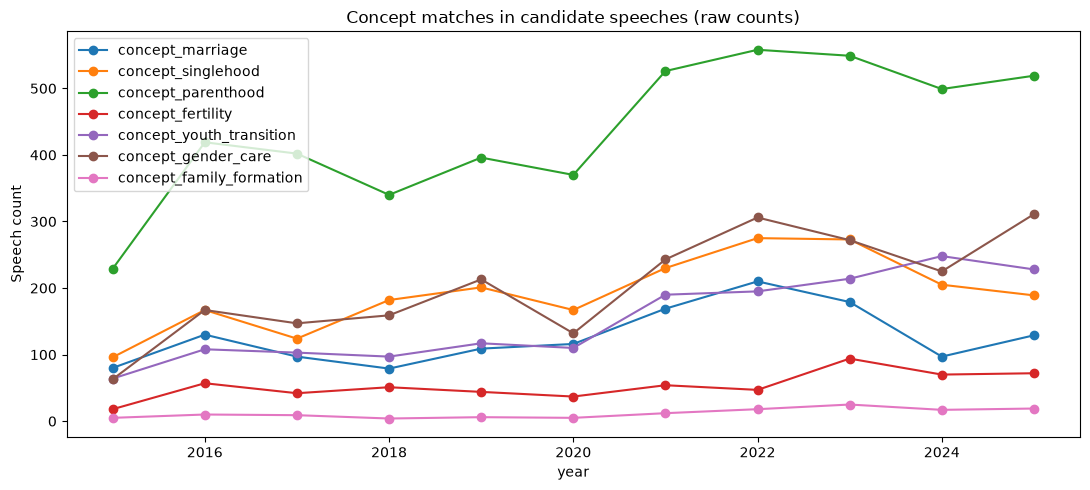

,concept_marriage,concept_singlehood,concept_parenthood,concept_fertility,concept_youth_transition,concept_gender_care,concept_family_formation
concept_marriage,1395,378,826,232,197,380,83
concept_singlehood,378,2109,839,156,194,389,57
concept_parenthood,826,839,4807,368,523,1115,97
concept_fertility,232,156,368,586,133,216,56
concept_youth_transition,197,194,523,133,1674,212,67
concept_gender_care,380,389,1115,216,212,2238,49
concept_family_formation,83,57,97,56,67,49,130


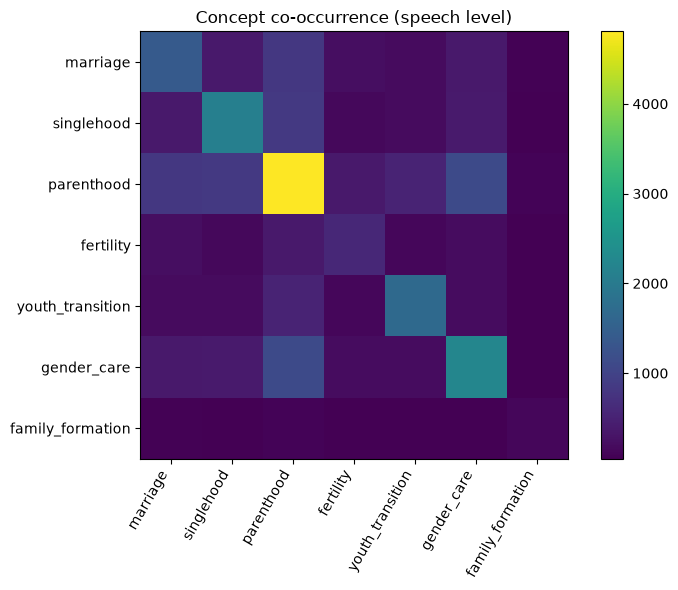

In [8]:
yearly=candidates.groupby('year')[concept_cols].sum()
yearly.plot(kind='line',marker='o',figsize=(11,5))
plt.title('Concept matches in candidate speeches (raw counts)');plt.ylabel('Speech count');plt.tight_layout();plt.show()
cooc=candidates[concept_cols].astype(int).T.dot(candidates[concept_cols].astype(int))
display(cooc)
fig,ax=plt.subplots(figsize=(8,6));im=ax.imshow(cooc.values)
ax.set_xticks(range(len(concept_cols)),[c.replace('concept_','') for c in concept_cols],rotation=60,ha='right')
ax.set_yticks(range(len(concept_cols)),[c.replace('concept_','') for c in concept_cols]);fig.colorbar(im,ax=ax)
plt.title('Concept co-occurrence (speech level)');plt.tight_layout();plt.show()


## 6. Balanced manual validation sample

We need **positive candidates and negative controls** to estimate both precision and missed relevant speeches. Sample from each available year; also include top-scoring speeches for rich qualitative cases. Edit the targets below as needed.

In [9]:
rng=np.random.default_rng(SEED)
SAMPLE_PER_YEAR_POS=12
SAMPLE_PER_YEAR_NEG=5
positive=[];negative=[]
for y in sorted(clean.year.unique()):
    p=candidates[candidates.year==y]
    q=clean[(clean.year==y)&(~clean.index.isin(candidates.index))]
    if len(p):positive.append(p.sample(n=min(SAMPLE_PER_YEAR_POS,len(p)),random_state=SEED))
    if len(q):negative.append(q.sample(n=min(SAMPLE_PER_YEAR_NEG,len(q)),random_state=SEED))
pos=pd.concat(positive) if positive else candidates.iloc[:0]
neg=pd.concat(negative) if negative else clean.iloc[:0]
# preserve source identity and ensure all samples include concept fields
sample=pd.concat([pos.assign(sample_stratum='candidate'),neg.assign(sample_stratum='negative_control')],ignore_index=True,sort=False)
for c in ['speech_id','topic_id','member_name','party','gender']:
    if c not in sample: sample[c]=pd.NA
sample['snippet']=sample.text.map(context_snippet)
sample=add_trigger_columns(sample)
manual_cols=['year','date','speech_id','topic_id','member_name','party','gender','sample_stratum','trigger_concept_categories','trigger_concept_terms','trigger_frame_categories','trigger_frame_terms','snippet','text']
manual=sample[manual_cols].copy()
manual['relevant_to_research']='' # yes/no/uncertain
manual['primary_theme']='' # marriage/singlehood/parenthood/youth/gender/other
for frame in FRAMES:manual['human_frame_'+frame]='' # 1/0/uncertain
manual['normative_stance']='' # endorses/challenges/descriptive/mixed/unclear
manual['target_group']='' # young adults/women/men/parents/singles/general/other
manual['evidence_quote']=''
manual['coder_notes']=''
manual.to_csv(OUT/'manual_validation_sample.csv',index=False,encoding='utf-8-sig')
print('Manual coding sample:',len(manual),'| candidates:',len(pos),'| negative controls:',len(neg))
display(manual[['year','member_name','sample_stratum','snippet']].head(12))


Manual coding sample: 187 | candidates: 132 | negative controls: 55


,year,member_name,sample_stratum,snippet
0,2015,Tin Pei Ling,candidate,asked the Minister for National Development (a) how many Built-To-Order (BTO) and Sale of Balance Flats (SBF) applications under the Married Child Priority Scheme (MCPS) have been made each year from 2011 to date; (b) how man...
1,2015,Dr Lee Bee Wah,candidate,…ter for Social and Family Development in light of the recent case of unauthorised withdrawal of funds from the Child Development Account (CDA) (a) what is the Ministry doing to tighten control over the CDA; (b) how will the M...
2,2015,Yee Jenn Jong,candidate,"… student care centres (SSCs) last week. Even as we increase the number of centres, a concern will be the availability of dedicated and trained staff. Since 2000, the Ministry has made steady progress in attracting and trainin..."
3,2015,Benedict Tan,candidate,"Madam, following my speech in Parliament on 19 January this year where I identified 10 worrying trends in Singapore's sports participation, many parents and students as well as Members of this House approached me to personally..."
4,2015,Hri Kumar Nair,candidate,"…, presentation and, ultimately, persuasion. Because much of what we do in life involves persuading someone else of something. If we can agree that an important objective of our education system should be to produce articulate..."
5,2015,Sylvia Lim,candidate,"…o being a playground for the rich, with Singapore being termed the world's newest Monaco in a 2013 article of the Wall Street Journal. One particular concern is to avoid poverty becoming entrenched across generations where ch..."
6,2015,Ong Teng Koon,candidate,"…e Act requires that all able-bodied and healthy men at the age of 18 are to undergo two years of military life. There was initial resistance from the community. Understandably so, because it essentially meant taking male chil..."
7,2015,Gerald Giam Yean Song,candidate,"asked the Deputy Prime Minister and Minister for Home Affairs as at 31 December 2014, how many foreign spouses of Singapore citizens have (i) social visit passes; (ii) Long Term Visit Passes (LTVP); and (iii) an immigration st..."
8,2015,Khaw Boon Wan,candidate,"…and for a comprehensive range of facilities, such as commercial centres, schools, parks and civic and community institutions. HDB has also launched several new BTO projects in the neighbourhood recently. The safeguarded facil..."
9,2015,Tin Pei Ling,candidate,asked the Minister for National Development whether HDB will consider raising the quota under the Married Child Priority Scheme for mature estates to encourage and better enable young couples to care for their elderly parents ...


## 7. Save all ranked candidates and representative cases

In [10]:
export_cols=[c for c in ['year','date','speech_id','topic_id','member_name','party','gender','word_count','concept_count','frame_hint_count','screening_score','snippet','text']+trigger_cols+['trigger_concept_'+k for k in CONCEPTS]+['trigger_frame_'+k for k in FRAMES]+concept_cols+[f'frame_hint_{k}' for k in FRAMES] if c in candidates.columns]
candidates[export_cols].sort_values(['screening_score','year'],ascending=[False,True]).to_csv(OUT/'all_candidate_speeches.csv',index=False,encoding='utf-8-sig')
# Max 3 from each topic per year among top-scoring, to avoid a single debate dominating examples
case_pool=candidates.sort_values(['screening_score','word_count'],ascending=False).groupby(['year','topic_id'],dropna=False).head(3)
cases=case_pool.groupby('year',group_keys=False).head(15)
cases[export_cols].to_csv(OUT/'qualitative_cases_by_year.csv',index=False,encoding='utf-8-sig')
print('Saved:',*[p.name for p in OUT.glob('*.csv')],sep='\n - ')


Saved:
 - qualitative_cases_by_year.csv
 - yearly_candidate_counts.csv
 - all_candidate_speeches.csv
 - manual_validation_sample.csv


## 8. Interpretation checklist (complete after human coding)

- **Precision:** Among sampled candidates, what proportion genuinely discuss normative adulthood / marriage / family formation?
- **Miss rate:** Among sampled negative controls, how many genuinely relevant passages were missed? (Do not assume zero.)
- **Frame evidence:** Which frames appear in the *same paragraph*, and is the speaker supporting, contesting, or merely describing the frame?
- **Temporal validity:** Do observed changes persist after accounting for annual speech totals, word counts, agenda composition and data coverage?
- **Actor comparison:** Compare parties/genders within the same topics where possible; missing party/gender values must be reported.
- **Selection:** If precision is low, refine vocabulary or build a supervised classifier before running any large-scale frame analysis.

**Research decision:** The corpus is promising if human reviewers find repeated, substantive normative claims across multiple years and agendas—not just a large number of generic matches.


## 9. Most frequent trigger terms

Counts below represent the number of candidate speeches containing each distinct matched expression (not total word occurrences).


In [11]:
from collections import Counter
for kind in ['concept', 'frame']:
    counter = Counter()
    for values in candidates['trigger_' + kind + '_terms']:
        counter.update(t for t in values.split(' | ') if t)
    freq = pd.DataFrame(counter.most_common(), columns=['matched_term', 'candidate_speeches'])
    freq.to_csv(OUT / f'{kind}_trigger_frequencies.csv', index=False, encoding='utf-8-sig')
    print(kind.upper(), 'most frequent matched expressions')
    display(freq.head(25))


CONCEPT most frequent matched expressions


,matched_term,candidate_speeches
0,parents,3336
1,single,1911
2,youth,1349
3,caregivers,906
4,childcare,822
5,mother,804
6,parent,738
7,caregiving,662
8,mothers,630
9,gender,535


FRAME most frequent matched expressions


,matched_term,candidate_speeches
0,housing,1287
1,mother,804
2,caregiving,662
3,mothers,630
4,affordable,617
5,aspirations,530
6,father,416
7,ageing population,372
8,affordability,274
9,fathers,268
